# Titanic Mini Visualization Dashboard: Task 4
### Data Science / Data Analysis with Python Internship, Main Crafts Technology

## Overview

This notebook is a **mini visualization dashboard** built with Matplotlib and Seaborn. The goal is to communicate the key insights in the Titanic dataset through well-chosen charts, each followed by a short interpretation.

**Dataset:** Kaggle Titanic `train.csv`, 891 passengers.

| Column | Meaning |
|---|---|
| `Survived` | 1 = survived, 0 = did not survive |
| `Pclass` | Passenger class (1 = highest, 3 = lowest) |
| `Sex`, `Age` | Passenger gender and age |
| `SibSp`, `Parch` | Siblings/spouses and parents/children aboard |
| `Fare` | Ticket price paid |
| `Embarked` | Port of embarkation (C, Q, S) |

**Dashboard contents:** 1) Age histogram, 2) Survival bar chart, 3) Fare boxplot, 4) Age vs Fare scatterplot, 5) Correlation heatmap, plus a bonus facet grid.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="muted")

# Folder for exported charts
os.makedirs('images', exist_ok=True)

### Load the data

`train.csv` comes from the [Kaggle Titanic competition page](https://www.kaggle.com/c/titanic/data). The code looks for the file in a `data/` folder first, then the working folder; if it is not found, Colab prompts for an upload.

In [2]:
# Look for the Kaggle file in data/ first, then the working folder
CANDIDATE_PATHS = ['data/train.csv', 'train.csv']
DATA_PATH = next((p for p in CANDIDATE_PATHS if os.path.exists(p)), None)

if DATA_PATH is None:
    from google.colab import files
    files.upload()  # select train.csv when prompted
    DATA_PATH = 'train.csv'

df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
df.head()

Shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


## Cleaning

First we find out what is missing, then fix it.

In [4]:
missing = df.isnull().sum()
print(missing[missing > 0])

Age         177
Cabin       687
Embarked      2
dtype: int64


`Age` is missing for 177 passengers, `Cabin` for 687 (about 77%) and `Embarked` for 2. We fill `Age` with the **median** (robust to outliers), fill `Embarked` with the **mode**, and drop `Cabin` because it is too sparse.

In [5]:
# Fill missing Age with the median
df['Age'] = df['Age'].fillna(df['Age'].median())

# Fill missing Embarked with the most common port
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])

# Drop the Cabin column (too many missing values)
df = df.drop(columns=['Cabin'], errors='ignore')

print("Remaining missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Remaining missing values: 0
Duplicate rows: 0


## Features

Two simple engineered features make the charts more meaningful:
- **FamilySize** = `SibSp` + `Parch` (relatives travelling with the passenger)
- **AgeGroup** = Child / Teen / YoungAdult / Adult / Senior

We also add a readable **Outcome** label for chart legends.

In [6]:
df['FamilySize'] = df['SibSp'] + df['Parch']

df['AgeGroup'] = pd.cut(
    df['Age'],
    bins=[0, 12, 18, 30, 50, 80],
    labels=['Child', 'Teen', 'YoungAdult', 'Adult', 'Senior']
)

df['Outcome'] = df['Survived'].map({0: 'Did not survive', 1: 'Survived'})

df[['Age', 'AgeGroup', 'SibSp', 'Parch', 'FamilySize', 'Outcome']].head()

,Age,AgeGroup,SibSp,Parch,FamilySize,Outcome
0,22.0,YoungAdult,1,0,1,Did not survive
1,38.0,Adult,1,0,1,Survived
2,26.0,YoungAdult,0,0,0,Survived
3,35.0,Adult,1,0,1,Survived
4,35.0,Adult,0,0,0,Did not survive


## Visualizations

Each chart is in its own cell and followed by a short interpretation. All charts are also exported to the `images/` folder.

### 1. Histogram: Age distribution

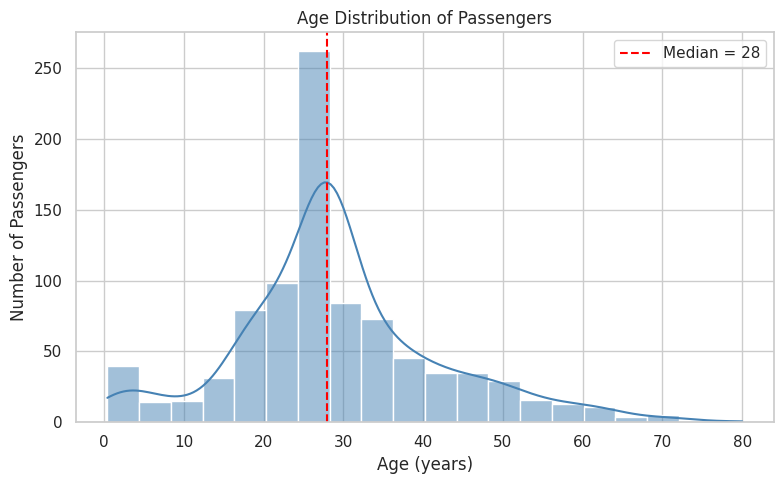

In [7]:
plt.figure(figsize=(8, 5))
sns.histplot(df['Age'], bins=20, kde=True, color='steelblue')
plt.axvline(df['Age'].median(), color='red', linestyle='--', label=f"Median = {df['Age'].median():.0f}")
plt.title('Age Distribution of Passengers')
plt.xlabel('Age (years)')
plt.ylabel('Number of Passengers')
plt.legend()
plt.tight_layout()
plt.savefig('images/01_age_histogram.png', dpi=150)
plt.show()

**Insight:** Most passengers were young adults aged 20-40, with a long tail of older passengers (right-skewed). The tall spike at 28 is an artefact of filling 177 missing ages with the median.

### 2. Bar chart: Survival rate by class and gender

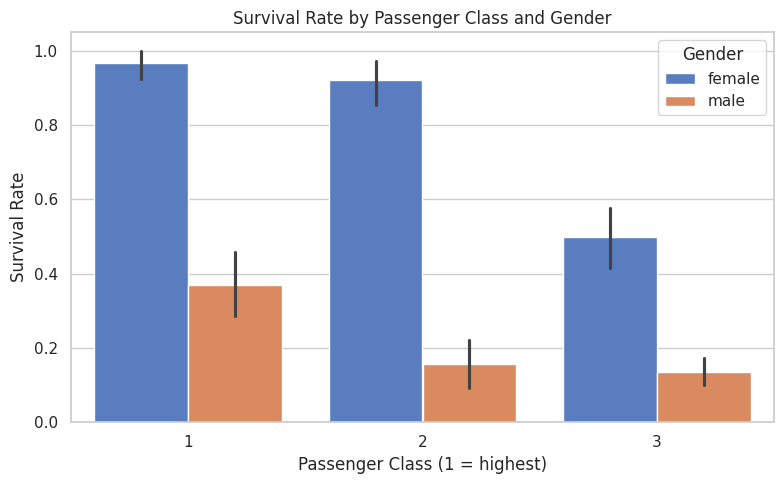

In [8]:
plt.figure(figsize=(8, 5))
sns.barplot(x='Pclass', y='Survived', hue='Sex', data=df)
plt.title('Survival Rate by Passenger Class and Gender')
plt.xlabel('Passenger Class (1 = highest)')
plt.ylabel('Survival Rate')
plt.legend(title='Gender')
plt.tight_layout()
plt.savefig('images/02_survival_by_class_gender.png', dpi=150)
plt.show()

**Insight:** Women survived far more often than men in **every** class (97% vs 37% in 1st, 92% vs 16% in 2nd, 50% vs 14% in 3rd). Gender mattered even more than class: 3rd-class women (50%) did better than 1st-class men (37%).